# Individual results: the life periods of Chinese individuals

In [1]:
import sys

import duckdb
import matplotlib.pyplot as plt
import polars as pl
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sys.path.insert(0, '../notebooks_analysis')
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
POLITY_DB_PATH = '../../data/cultura/humans_clean_enriched_v3.duckdb'  # read only: Chinese-world polities
BIRTH_YEARS = (600, 800)
MIN_AGE_AT_DEATH = 15  # years: younger deaths are left out
PER_CASE = {('wikidata', 'wikidata'): 4, ('estimated', 'wikidata'): 3, ('wikidata', 'estimated'): 3}  # individuals shown per (birth, death) source
PERIOD_COLORS = {'Pre-peak': ORANGE, 'Peak': BLUE, 'Post-peak': GREEN}
AGE_LABEL_GAP = 6  # years: a closer step shows only the later age
MIN_LENGTH_LABEL = 10  # years: a shorter period shows no length

apply_style()

## Data
Chinese individuals: Wikidata citizenship in a polity of the Chinese world. Pre-peak = birth → first work, peak = first → last work, post-peak = last work → death.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"ATTACH '{POLITY_DB_PATH}' AS polity_db (READ_ONLY)")
people = con.sql('''
    WITH chinese_polities AS (
        SELECT DISTINCT entity.qid AS polity_qid
        FROM   polity_db.polity
        WHERE  list_contains(world, 'Chinese world') AND entity.qid IS NOT NULL
    ),
    chinese AS (
        SELECT DISTINCT entity.qid AS qid, len(sitelink) AS sitelinks
        FROM   (SELECT entity, sitelink, unnest(country_of_citizenship) AS citizenship FROM individual)
        WHERE  citizenship.entity.qid IN (SELECT polity_qid FROM chinese_polities)
    )
    SELECT individual_enriched.entity.qid AS qid,
           individual_enriched.entity.label_en AS name,
           chinese.sitelinks,
           birth_date.year         AS birth_year,
           birth_date.source       AS birth_source,
           death_date.year         AS death_year,
           death_date.source       AS death_source,
           first_work_date.year    AS peak_start,
           last_work_date.year     AS peak_end,
           first_work_date.source  AS peak_source
    FROM   individual_enriched
    JOIN   chinese ON individual_enriched.entity.qid = chinese.qid
    WHERE  birth_date.year BETWEEN $first AND $last AND death_date.year IS NOT NULL AND first_work_date.year IS NOT NULL
''', params={'first': BIRTH_YEARS[0], 'last': BIRTH_YEARS[1]}).pl()
con.close()
assert people['qid'].n_unique() == people.height
print(f'{people.height:,} Chinese individuals born {BIRTH_YEARS[0]}–{BIRTH_YEARS[1]} with a birth, a death and a work period')
people.group_by('birth_source', 'death_source').len().sort('len', descending=True)

19,780 Chinese individuals born 600–800 with a birth, a death and a work period


birth_source,death_source,len
str,str,u32
"""estimated""","""wikidata""",16047
"""wikidata""","""wikidata""",3637
"""wikidata""","""estimated""",96


## Individuals shown
The most-linked individuals (Wikipedia pages) of each case: both dates from Wikidata, an estimated birth, an estimated death; named, dead at 15 or older.

In [3]:
shown = pl.concat([
    people.filter((pl.col('birth_source') == birth) & (pl.col('death_source') == death)
                  & pl.col('name').is_not_null() & (pl.col('death_year') - pl.col('birth_year') >= MIN_AGE_AT_DEATH))
    .sort('sitelinks', descending=True).head(n)
    for (birth, death), n in PER_CASE.items()
]).sort('birth_year', descending=True)
assert shown.height == sum(PER_CASE.values())
shown

qid,name,sitelinks,birth_year,birth_source,death_year,death_source,peak_start,peak_end,peak_source
str,str,i64,i64,str,i64,str,i64,i64,str
"""Q971072""","""Han Xiang""",16,794,"""wikidata""",868,"""estimated""",847,864,"""estimated"""
"""Q326950""","""Linji Yixuan""",27,793,"""estimated""",867,"""wikidata""",846,863,"""estimated"""
"""Q1632823""","""Huangbo Xiyun""",16,781,"""estimated""",855,"""wikidata""",834,851,"""estimated"""
"""Q33772""","""Du Fu""",136,712,"""wikidata""",770,"""wikidata""",753,768,"""estimated"""
"""Q7071""","""Li Bai""",191,701,"""wikidata""",762,"""wikidata""",742,757,"""estimated"""
"""Q455589""","""Meng Haoran""",36,676,"""estimated""",740,"""wikidata""",717,732,"""estimated"""
"""Q717343""","""Zhang Xu""",13,670,"""wikidata""",734,"""estimated""",711,726,"""estimated"""
"""Q9738""","""Wu Zetian""",72,624,"""wikidata""",705,"""wikidata""",672,693,"""estimated"""
"""Q42063""","""Xuanzang""",76,602,"""wikidata""",664,"""wikidata""",655,664,"""estimated"""


## Figure: pre-peak, peak and post-peak periods of 10 Chinese individuals born 600–800

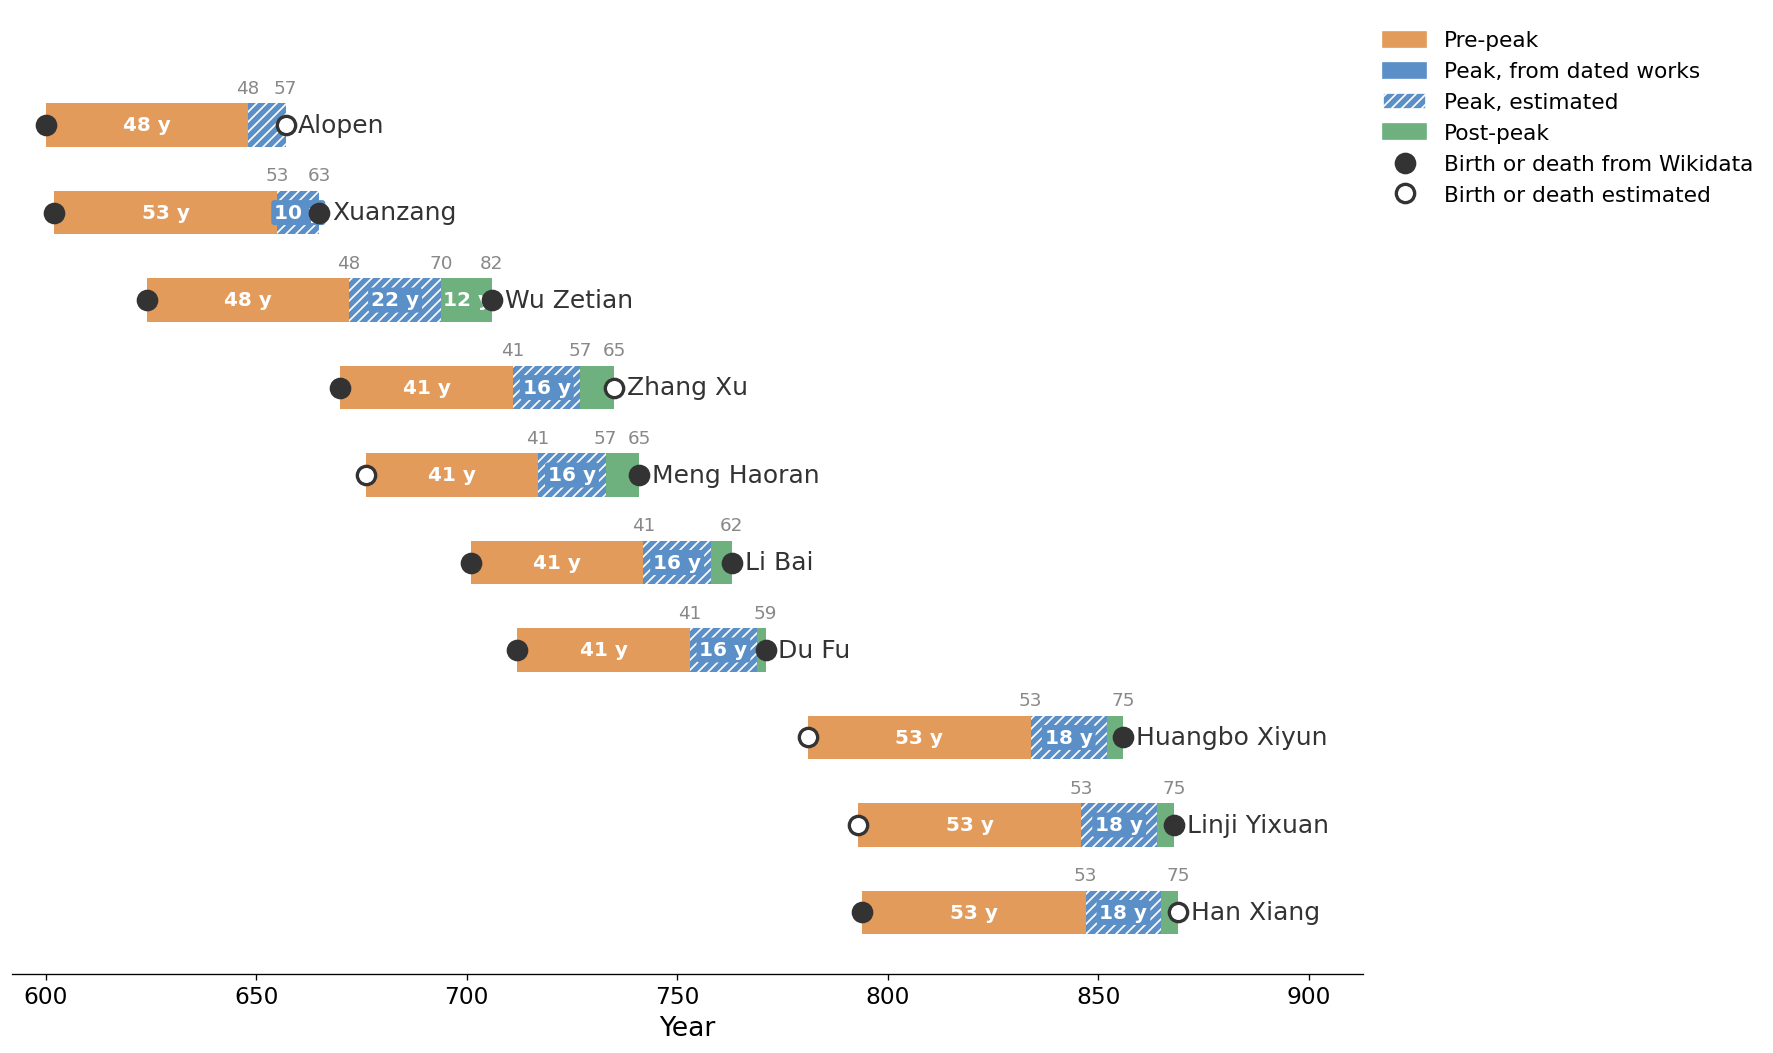

In [4]:
fig, ax = plt.subplots(figsize=(15, 9))
for row, person in enumerate(shown.iter_rows(named=True)):
    periods = [
        ('Pre-peak', person['birth_year'], person['peak_start']),
        ('Peak', person['peak_start'], person['peak_end'] + 1),
        ('Post-peak', person['peak_end'] + 1, person['death_year'] + 1),
    ]
    for period, start, end in periods:
        if end > start:
            estimated = period == 'Peak' and person['peak_source'] == 'estimated'
            ax.barh(row, end - start, left=start, height=0.5, color=PERIOD_COLORS[period], hatch='////' if estimated else None, edgecolor='white', linewidth=0)
            if end - start >= MIN_LENGTH_LABEL:
                ax.text((start + end) / 2, row, f'{end - start} y', ha='center', va='center', fontsize=12, color='white', fontweight='bold',
                        bbox={'boxstyle': 'round,pad=0.15', 'facecolor': PERIOD_COLORS[period], 'edgecolor': 'none'} if estimated else None)
    for year, source in [(person['birth_year'], person['birth_source']), (person['death_year'] + 1, person['death_source'])]:
        ax.plot(year, row, 'o', markersize=11, markeredgewidth=2, color=TEXT, markerfacecolor='white' if source == 'estimated' else TEXT, zorder=3)
    steps = [person['peak_start'], person['peak_end'] + 1, person['death_year'] + 1]
    ages = [year for i, year in enumerate(steps) if i == len(steps) - 1 or steps[i + 1] - year >= AGE_LABEL_GAP]
    for year in ages:
        ax.text(year, row + 0.32, year - person['birth_year'], ha='center', va='bottom', fontsize=POINT_LABEL_FONTSIZE, color=MUTED_TEXT)
    ax.text(person['death_year'] + 4, row, person['name'], va='center', fontsize=15, color=TEXT)

ax.legend(handles=[
    Patch(color=PERIOD_COLORS['Pre-peak'], label='Pre-peak'),
    Patch(color=PERIOD_COLORS['Peak'], label='Peak, from dated works'),
    Patch(facecolor=PERIOD_COLORS['Peak'], hatch='////', edgecolor='white', label='Peak, estimated'),
    Patch(color=PERIOD_COLORS['Post-peak'], label='Post-peak'),
    Line2D([], [], marker='o', linestyle='', markersize=11, markeredgewidth=2, color=TEXT, label='Birth or death from Wikidata'),
    Line2D([], [], marker='o', linestyle='', markersize=11, markeredgewidth=2, color=TEXT, markerfacecolor='white', label='Birth or death estimated'),
], loc='upper left', bbox_to_anchor=(1, 1), fontsize=13)
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_ylim(-0.7, shown.height + 0.3)
ax.set_xlim(shown['birth_year'].min() - 8, shown['death_year'].max() + 45)
ax.set_xlabel('Year')
plt.tight_layout()
plt.show()